# Bonus Project: Object Detection on the African Wildlife Dataset
**CSCI1409 Deep Learning, KBTU, Fall 2026**

Goal: fine-tune a pretrained YOLO detector to find 4 animal classes (buffalo, elephant, rhino, zebra).

Run the cells from top to bottom. Use a GPU runtime: **Runtime → Change runtime type → T4 GPU**.

## 0. Setup
Check that a GPU is available and install the dependencies.

In [ ]:
!nvidia-smi

Fri Nov 20 07:28:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# Install the Ultralytics YOLO framework
!pip install -q ultralytics

import ultralytics, torch, sys
print("Python      :", sys.version.split()[0])
print("Ultralytics :", ultralytics.__version__)
print("PyTorch     :", torch.__version__)
print("CUDA GPU    :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "not available")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python      : 3.13.16
Ultralytics : 8.4.216
PyTorch     : 2.14.1+cu130
CUDA GPU    : Tesla T4


In [ ]:
import os, random, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

OUT = Path("outputs")          # all figures and tables for the README are saved here
OUT.mkdir(exist_ok=True)

## 1. Dataset

**African Wildlife** (Ultralytics adaptation of the dataset by Bianca Ferreira, Kaggle).
- 4 classes: buffalo, elephant, rhino, zebra
- Annotation format: YOLO (one `.txt` per image, one line per object: `class x_center y_center width height`, normalized to 0–1)
- The dataset is already split into train / val / test by its authors, but we found duplicates across splits and fix this in section 1.5.

The cell below downloads the dataset (~100 MB) and returns its paths.

In [ ]:
from ultralytics.data.utils import check_det_dataset

data = check_det_dataset("african-wildlife.yaml")   # downloads the dataset if needed
CLASS_NAMES = data["names"]                          # {0: 'buffalo', 1: 'elephant', ...}
SPLITS = {s: Path(data[s]) for s in ["train", "val", "test"]}

print("Classes:", CLASS_NAMES)
for s, p in SPLITS.items():
    print(f"{s:5s} images folder: {p}")


WARNING ⚠️ Dataset 'african-wildlife.yaml' images not found, missing path '/content/datasets/african-wildlife/images/val'
Unzipping /content/datasets/african-wildlife.zip to /content/datasets/african-wildlife...: 100% ━━━━━━━━━━━━ 3018/3018 1.5Kfiles/s 2.0s
Dataset download success ✅ (4.3s), saved to /content/datasets

Classes: {0: 'buffalo', 1: 'elephant', 2: 'rhino', 3: 'zebra'}
train images folder: /content/datasets/african-wildlife/images/train
val   images folder: /content/datasets/african-wildlife/images/val
test  images folder: /content/datasets/african-wildlife/images/test


In [ ]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def list_images(img_dir):
    return sorted(p for p in Path(img_dir).iterdir() if p.suffix.lower() in IMG_EXT)

def label_path(img_path):
    # YOLO convention: .../images/xxx.jpg  ->  .../labels/xxx.txt
    parts = list(img_path.parts)
    i = len(parts) - 1 - parts[::-1].index("images")
    parts[i] = "labels"
    return Path(*parts).with_suffix(".txt")

def read_labels(img_path):
    """Returns a list of (class_id, xc, yc, w, h) and a list of malformed lines."""
    lp = label_path(img_path)
    boxes, bad = [], []
    if not lp.exists():
        return None, bad
    for line in lp.read_text().strip().splitlines():
        v = line.split()
        if len(v) != 5:
            bad.append(line); continue
        try:
            boxes.append((int(float(v[0])), *map(float, v[1:])))
        except ValueError:
            bad.append(line)
    return boxes, bad

images = {s: list_images(p) for s, p in SPLITS.items()}

### 1.1 Number of images and objects per split

In [ ]:
def dataset_stats(images):
    rows = []
    for s, imgs in images.items():
        row = {"split": s, "images": len(imgs), "objects": 0}
        for c in CLASS_NAMES.values():
            row[c] = 0
        for img in imgs:
            boxes, _ = read_labels(img)
            for b in boxes or []:
                row["objects"] += 1
                if b[0] in CLASS_NAMES:
                    row[CLASS_NAMES[b[0]]] += 1
        rows.append(row)
    stats = pd.DataFrame(rows)
    total = stats.drop(columns="split").sum()
    total["split"] = "total"
    return pd.concat([stats, total.to_frame().T], ignore_index=True)

stats = dataset_stats(images)
stats.to_csv(OUT / "dataset_stats_original.csv", index=False)
stats

,split,images,objects,buffalo,elephant,rhino,zebra
0,train,1052,1931,399,558,399,575
1,val,225,379,89,91,85,114
2,test,227,375,66,99,75,135
3,total,1504,2685,554,748,559,824


### 1.2 Ground-truth examples
At least five images with their ground-truth (human-annotated) boxes.

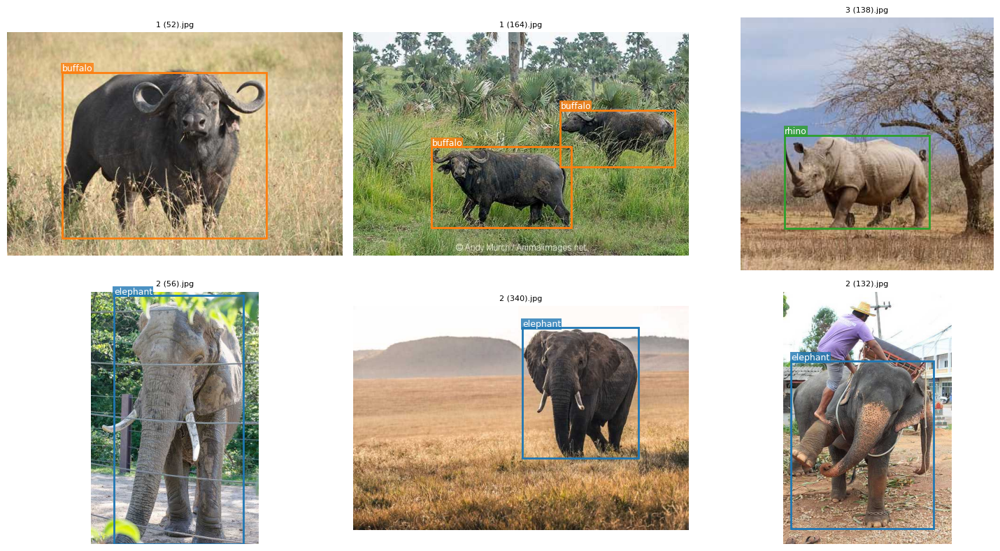

In [ ]:
COLORS = {0: "tab:orange", 1: "tab:blue", 2: "tab:green", 3: "tab:red"}

def draw_gt(ax, img_path):
    img = Image.open(img_path).convert("RGB")
    W, H = img.size
    ax.imshow(img)
    boxes, _ = read_labels(img_path)
    for cls, xc, yc, w, h in boxes or []:
        x0, y0 = (xc - w / 2) * W, (yc - h / 2) * H
        color = COLORS.get(cls, "white")
        ax.add_patch(patches.Rectangle((x0, y0), w * W, h * H, fill=False, lw=2, edgecolor=color))
        ax.text(x0, y0 - 3, CLASS_NAMES.get(cls, f"id {cls}"), color="white", fontsize=9,
                bbox=dict(facecolor=color, alpha=0.8, pad=1, lw=0))
    ax.set_title(img_path.name, fontsize=8)
    ax.axis("off")

def show_grid(paths, fname, cols=3):
    rows_n = int(np.ceil(len(paths) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(5 * cols, 4 * rows_n))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, p in zip(np.ravel(axes), paths):
        draw_gt(ax, p)
    plt.tight_layout()
    plt.savefig(OUT / fname, dpi=100, bbox_inches="tight")
    plt.show()

rng = random.Random(SEED)
examples = rng.sample(images["train"], 6)
show_grid(examples, "gt_examples.png")

### 1.3 Label quality check
**Automatic check** of all label files for:
missing label files, empty label files, malformed lines, invalid class IDs,
boxes outside the image (coordinates outside 0–1), and very small boxes (possible accidental clicks).

In [ ]:
TINY = 0.0005   # box area < 0.05% of the image is treated as suspicious

issues = {k: [] for k in ["missing_label_file", "empty_label_file", "malformed_line",
                          "invalid_class_id", "box_outside_image", "tiny_box"]}

for s, imgs in images.items():
    for img in imgs:
        boxes, bad = read_labels(img)
        if boxes is None:
            issues["missing_label_file"].append((s, img.name)); continue
        if not boxes and not bad:
            issues["empty_label_file"].append((s, img.name))
        for line in bad:
            issues["malformed_line"].append((s, img.name, line))
        for cls, xc, yc, w, h in boxes:
            if cls not in CLASS_NAMES:
                issues["invalid_class_id"].append((s, img.name, cls))
            if (xc - w / 2 < -1e-3 or yc - h / 2 < -1e-3 or
                xc + w / 2 > 1 + 1e-3 or yc + h / 2 > 1 + 1e-3 or w <= 0 or h <= 0):
                issues["box_outside_image"].append((s, img.name, round(xc, 3), round(yc, 3), round(w, 3), round(h, 3)))
            if w * h < TINY:
                issues["tiny_box"].append((s, img.name, round(w * h, 6)))

summary = pd.DataFrame({"issue": list(issues), "count": [len(v) for v in issues.values()]})
summary.to_csv(OUT / "label_check.csv", index=False)
display(summary)
for k, v in issues.items():
    if v:
        print(f"\n{k} (first 5):")
        for item in v[:5]:
            print("  ", item)

,issue,count
0,missing_label_file,0
1,empty_label_file,0
2,malformed_line,0
3,invalid_class_id,0
4,box_outside_image,0
5,tiny_box,0


**Visual check.** Code cannot see a forgotten animal or a wrong class, so we look at random images ourselves.
Look at each image: is every animal boxed? Is each class name correct? Write down anything wrong.

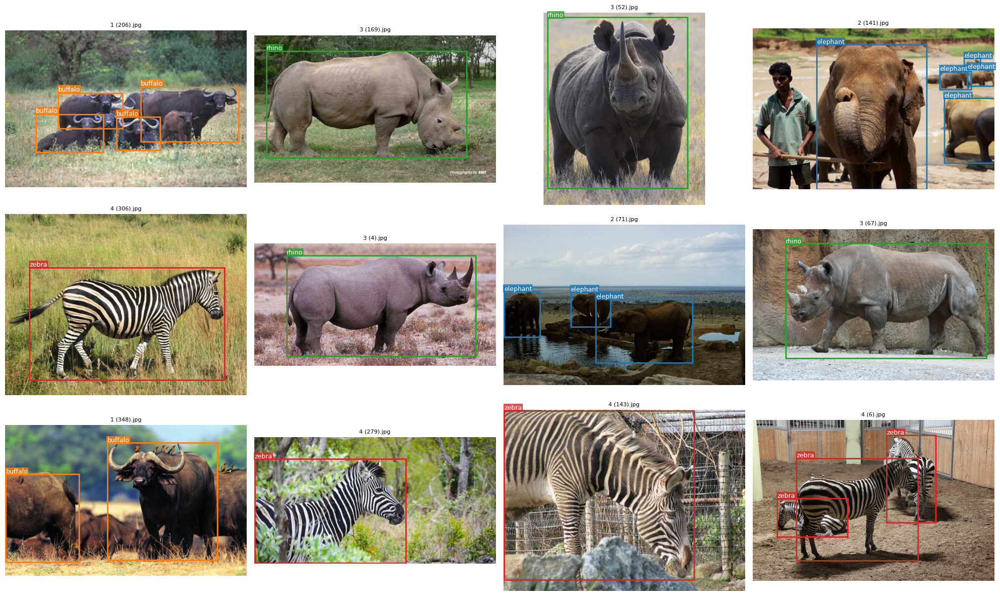

In [ ]:
rng = random.Random(SEED + 1)
all_imgs = images["train"] + images["val"] + images["test"]
show_grid(rng.sample(all_imgs, 12), "visual_check.png", cols=4)

In [ ]:
# If the automatic check found tiny boxes or boxes outside the image, show those images here
flagged = []
for k in ["tiny_box", "box_outside_image"]:
    for item in issues[k]:
        s, name = item[0], item[1]
        p = SPLITS[s] / name
        if p not in flagged:
            flagged.append(p)
if flagged:
    show_grid(flagged[:6], "flagged_labels.png")
else:
    print("No flagged images to show.")

No flagged images to show.


### 1.4 Duplicate check between splits
Duplicates or near-duplicates in different splits would leak information from train into val/test
and make the results look better than they are.
- **Exact duplicates:** identical file content (MD5 hash).
- **Near-duplicates:** perceptual hash (dHash, 64 bits); two images whose hashes differ in ≤ 5 bits look almost the same.

In [ ]:
def md5(p):
    return hashlib.md5(p.read_bytes()).hexdigest()

def dhash(p, size=8):
    img = Image.open(p).convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(img, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()

THRESH = 5   # max number of different bits for two images to count as near-duplicates

def hash_table(images):
    recs = [{"split": s, "path": p, "md5": md5(p), "dhash": dhash(p)}
            for s, imgs in images.items() for p in imgs]
    return pd.DataFrame(recs)

def cross_split_duplicates(df):
    # exact duplicates: same MD5 in more than one split
    exact = df.groupby("md5")["split"].nunique()
    n_exact = int((exact > 1).sum())
    # near-duplicates: compare every val/test image with all images from other splits
    H = np.stack(df["dhash"].values)
    sp = df["split"].values
    near = []
    for i in range(len(df)):
        if sp[i] == "train":
            continue
        d = (H != H[i]).sum(axis=1)
        for j in np.where((d <= THRESH) & (sp != sp[i]))[0]:
            if sp[j] == "train" or j > i:
                near.append((df.path[i].name, sp[i], df.path[j].name, sp[j], int(d[j])))
    near_df = pd.DataFrame(near, columns=["image_a", "split_a", "image_b", "split_b", "hash_distance"])
    return n_exact, near_df

hashes = hash_table(images)
n_exact, near_df = cross_split_duplicates(hashes)
near_df.to_csv(OUT / "near_duplicates_original.csv", index=False)
print("Exact duplicates across splits:", n_exact)
print(f"Near-duplicate pairs across splits (distance <= {THRESH}):", len(near_df))
near_df.head(10)

Exact duplicates across splits: 20
Near-duplicate pairs across splits (distance <= 5): 33


,image_a,split_a,image_b,split_b,hash_distance
0,1 (122).jpg,val,1 (124).jpg,train,0
1,1 (223).jpg,val,1 (229).jpg,train,0
2,1 (334).jpg,val,1 (360).jpg,train,0
3,1 (334).jpg,val,1 (98).jpg,train,0
4,2 (355).jpg,val,2 (237).jpg,train,0
5,3 (226).jpg,val,3 (230).jpg,train,0
6,3 (269).jpg,val,3 (83).jpg,test,0
7,3 (318).jpg,val,3 (83).jpg,test,0
8,3 (326).jpg,val,3 (235).jpg,train,0
9,3 (364).jpg,val,3 (311).jpg,train,0


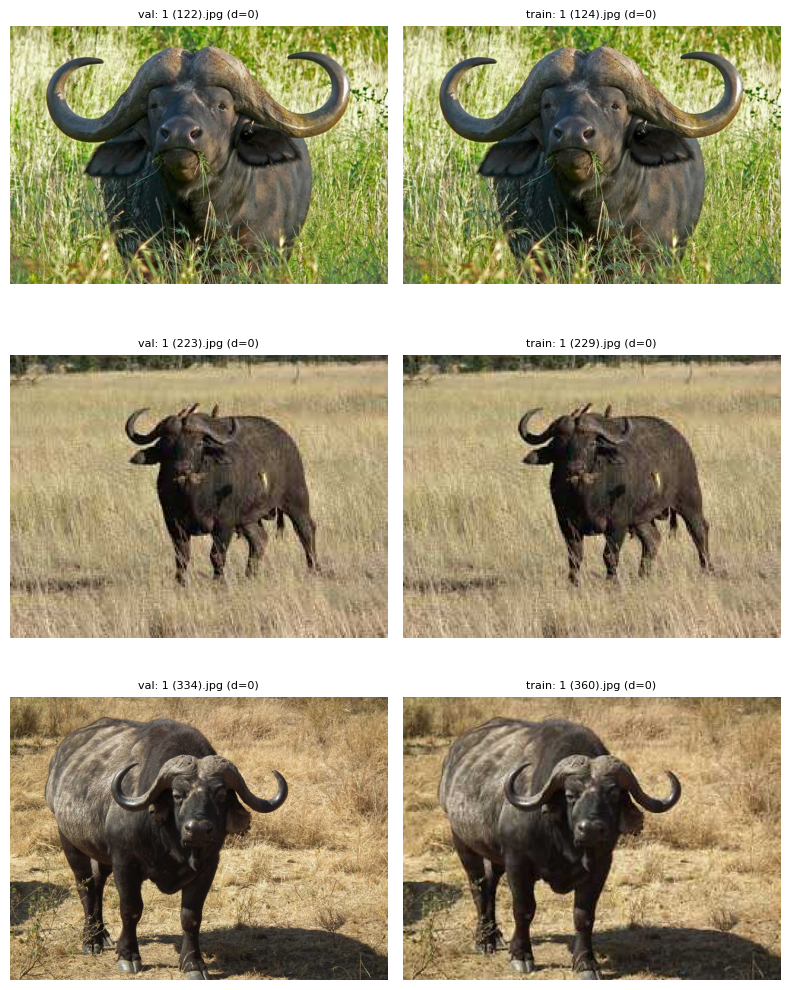

In [ ]:
# Show up to 3 near-duplicate pairs side by side so we can judge them by eye
if len(near_df):
    k = min(3, len(near_df))
    fig, axes = plt.subplots(k, 2, figsize=(8, 3.5 * k))
    axes = np.atleast_2d(axes)
    for r in range(k):
        row = near_df.iloc[r]
        for c, (name, s) in enumerate([(row.image_a, row.split_a), (row.image_b, row.split_b)]):
            axes[r, c].imshow(Image.open(SPLITS[s] / name))
            axes[r, c].set_title(f"{s}: {name} (d={row.hash_distance})", fontsize=8)
            axes[r, c].axis("off")
    plt.tight_layout()
    plt.savefig(OUT / "near_duplicates.png", dpi=100, bbox_inches="tight")
    plt.show()
else:
    print("No near-duplicates across splits found.")

### 1.5 Fixing the split (removing leakage)
The check above found the same photos in different splits. To follow the rule
*"keep duplicates and near-duplicates in the same split"*, we:
1. Group images that are exact or near-duplicates of each other (MD5 match or dHash distance ≤ 5), over **all** images.
2. If a group spans more than one split, move the whole group to **train** (val and test stay clean).
3. Copy the result into a new folder `african-wildlife-clean` and write a new `data.yaml`.

The procedure is deterministic (no randomness), so no random seed is needed. Moved files are renamed
`from<split>_<name>` to avoid file-name collisions, and listed in `outputs/split_changes.csv`.

In [ ]:
import shutil, yaml

# --- 1. group duplicates with union-find ---
parent = list(range(len(hashes)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def union(i, j):
    parent[find(i)] = find(j)

H = np.stack(hashes["dhash"].values)
md5s = hashes["md5"].values
for i in range(len(hashes)):
    d = (H[i + 1:] != H[i]).sum(axis=1)
    for j in np.where((d <= THRESH) | (md5s[i + 1:] == md5s[i]))[0]:
        union(i, i + 1 + j)
hashes["group"] = [find(i) for i in range(len(hashes))]

# --- 2. groups that span several splits go to train ---
spans = hashes.groupby("group")["split"].nunique()
mixed = set(spans[spans > 1].index)
hashes["new_split"] = np.where(hashes["group"].isin(mixed), "train", hashes["split"])
moved = hashes[hashes["split"] != hashes["new_split"]]
print("Groups spanning several splits:", len(mixed))
print("Images moved to train:", len(moved))

# --- 3. write the clean dataset ---
CLEAN = Path(data["path"]).parent / "african-wildlife-clean"
if CLEAN.exists():
    shutil.rmtree(CLEAN)
changes = []
for _, r in hashes.iterrows():
    src_img = r.path
    name = src_img.name if r.split == r.new_split else f"from{r.split}_{src_img.name}"
    dst_img = CLEAN / "images" / r.new_split / name
    dst_lbl = CLEAN / "labels" / r.new_split / Path(name).with_suffix(".txt")
    assert not dst_img.exists(), f"name collision: {dst_img}"
    dst_img.parent.mkdir(parents=True, exist_ok=True)
    dst_lbl.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src_img, dst_img)
    if label_path(src_img).exists():
        shutil.copy2(label_path(src_img), dst_lbl)
    if r.split != r.new_split:
        changes.append({"original_split": r.split, "original_name": src_img.name,
                        "new_split": r.new_split, "new_name": name})
pd.DataFrame(changes).to_csv(OUT / "split_changes.csv", index=False)

DATA_YAML = Path("african-wildlife-clean.yaml").resolve()
with open(DATA_YAML, "w") as f:
    yaml.safe_dump({"path": str(CLEAN), "train": "images/train", "val": "images/val",
                    "test": "images/test", "names": CLASS_NAMES}, f, sort_keys=False)
print("New dataset config:", DATA_YAML)
print(open(DATA_YAML).read())

Groups spanning several splits: 29
Images moved to train: 31
New dataset config: /content/african-wildlife-clean.yaml
path: /content/datasets/african-wildlife-clean
train: images/train
val: images/val
test: images/test
names:
  0: buffalo
  1: elephant
  2: rhino
  3: zebra



**Check the clean dataset:** new counts per split, and the duplicate check again (should be 0).

In [ ]:
SPLITS = {s: CLEAN / "images" / s for s in ["train", "val", "test"]}
images = {s: list_images(p) for s, p in SPLITS.items()}

stats_clean = dataset_stats(images)
stats_clean.to_csv(OUT / "dataset_stats.csv", index=False)
display(stats_clean)

n_exact2, near_df2 = cross_split_duplicates(hash_table(images))
print("Exact duplicates across splits:", n_exact2)
print("Near-duplicate pairs across splits:", len(near_df2))

,split,images,objects,buffalo,elephant,rhino,zebra
0,train,1083,1981,416,565,413,587
1,val,215,363,86,87,79,111
2,test,206,341,52,96,67,126
3,total,1504,2685,554,748,559,824


Exact duplicates across splits: 0
Near-duplicate pairs across splits: 0


## 2. Baseline training
We fine-tune a YOLO11n model pretrained on COCO (`yolo11n.pt`).
All important settings are written explicitly so they are recorded:
the optimizer is fixed to SGD so that the learning rate we set is actually used
(with `optimizer="auto"` Ultralytics would choose its own learning rate).

In [ ]:
import time, json, shutil
from ultralytics import YOLO

BASE = dict(
    data=str(DATA_YAML),
    epochs=30,
    imgsz=640,
    batch=16,
    optimizer="SGD",
    lr0=0.01,          # initial learning rate
    momentum=0.937,
    seed=SEED,
    deterministic=True,
    pretrained=True,
    patience=100,      # no early stopping, all 30 epochs are run
    plots=True,
    exist_ok=True,
    project="runs",
)
PRETRAINED = "yolo11n.pt"   # initial weights (COCO-pretrained), the same for both runs

def train_run(name, **changes):
    cfg = {**BASE, **changes, "name": name}
    model = YOLO(PRETRAINED)
    t0 = time.time()
    model.train(**cfg)
    minutes = (time.time() - t0) / 60
    save_dir = Path(model.trainer.save_dir)
    # copy the evidence for the README into outputs/
    for f in ["args.yaml", "results.csv", "results.png"]:
        if (save_dir / f).exists():
            shutil.copy2(save_dir / f, OUT / f"{name}_{f}")
    info = {"run": name, "save_dir": str(save_dir), "train_minutes": round(minutes, 1),
            "best": str(save_dir / "weights" / "best.pt"), "config": {k: v for k, v in cfg.items()}}
    json.dump(info, open(OUT / f"{name}_info.json", "w"), indent=2)
    print(f"\n{name}: training time {minutes:.1f} min, saved in {save_dir}")
    return info

baseline = train_run("baseline")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/african-wildlife-clean.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline, nbs=64, nms=None, opset=None, optimize=Fals

Learning curves of the baseline (losses go down, metrics go up). The best checkpoint `best.pt`
is the epoch with the best validation fitness (mainly mAP50-95), selected automatically by Ultralytics.

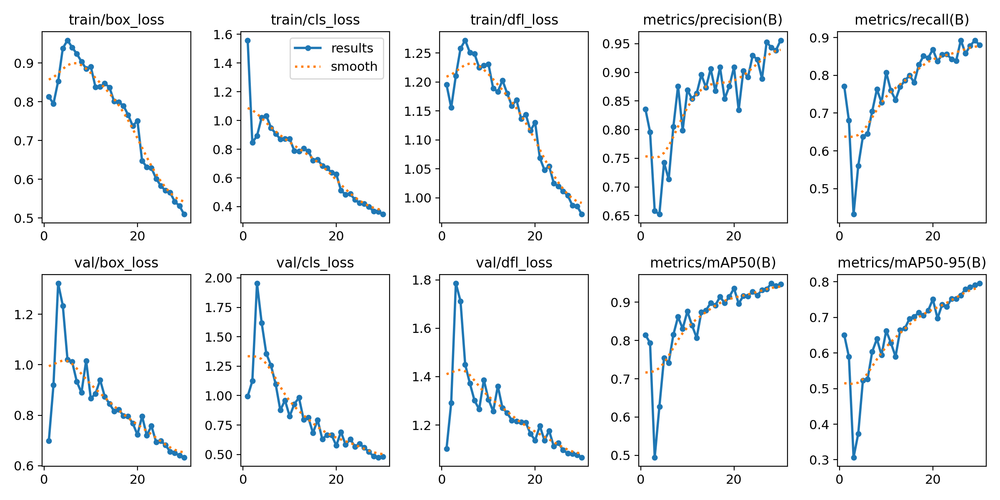

In [ ]:
from IPython.display import Image as IPImage, display
display(IPImage(filename=str(OUT / "baseline_results.png"), width=900))

## 3. Controlled experiment: image size
**Changed setting:** `imgsz` 640 → **320**. Everything else is identical (same data split,
same pretrained weights `yolo11n.pt`, same epochs, batch, learning rate and seed).

**Hypothesis (written before seeing the results):** with 320-px images the model sees 4× fewer pixels,
so training will be noticeably faster, but precision, recall and mAP@0.50 on the validation set will be
somewhat lower, because small and distant animals lose detail.

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/african-wildlife-clean.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=imgsz320, nbs=64, nms=None, opset=None, optimize=Fals

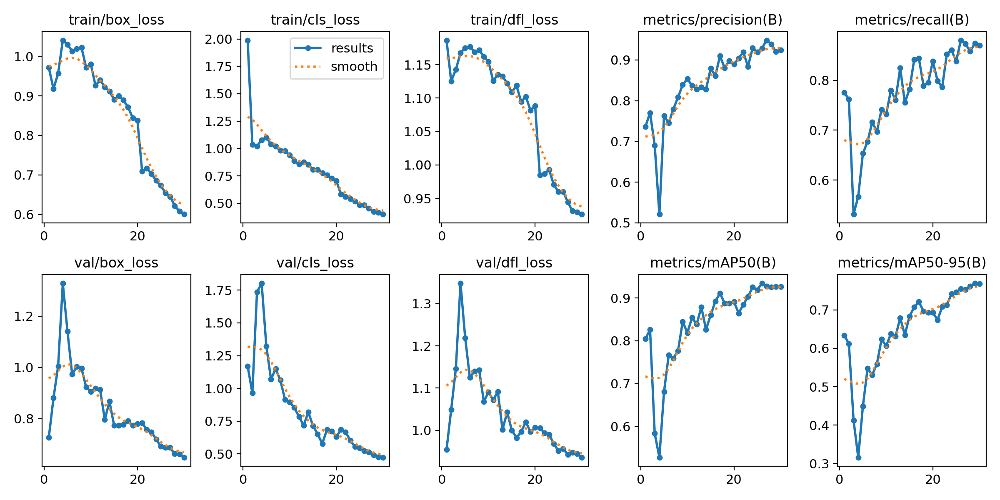

In [ ]:
small = train_run("imgsz320", imgsz=320)
display(IPImage(filename=str(OUT / "imgsz320_results.png"), width=900))

### Comparison on the validation set
Both best checkpoints are evaluated on the **validation** set (the test set is not used here).
Each model is evaluated at the image size it was trained with.

In [ ]:
def evaluate(info, split, imgsz):
    m = YOLO(info["best"])
    r = m.val(data=str(DATA_YAML), split=split, imgsz=imgsz, batch=16,
              conf=0.001, iou=0.7, plots=True, project="runs", name=f"{info['run']}_{split}", exist_ok=True)
    return {"run": info["run"], "imgsz": imgsz,
            "precision": round(float(r.box.mp), 3), "recall": round(float(r.box.mr), 3),
            "mAP@0.50": round(float(r.box.map50), 3), "mAP@0.50:0.95": round(float(r.box.map), 3),
            "train_minutes": info["train_minutes"]}

comparison = pd.DataFrame([evaluate(baseline, "val", 640), evaluate(small, "val", 320)])
comparison.insert(1, "changed setting", ["imgsz=640 (baseline)", "imgsz=320"])
comparison.to_csv(OUT / "experiment_comparison.csv", index=False)
comparison

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1603.1±648.5 MB/s, size: 43.4 KB)
val: Scanning /content/datasets/african-wildlife-clean/labels/val.cache... 215 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 215/215 75.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 5.2it/s 2.7s
                   all        215        363      0.958      0.879      0.948      0.796
               buffalo         59         86      0.944      0.895       0.95      0.794
              elephant         52         87      0.956      0.805      0.916      0.781
                 rhino         50         79      0.961      0.942      0.976      0.845
                 zebra         58        111       0.97      0.873      0.951      0.762
Speed: 1.2ms preprocess

,run,changed setting,imgsz,precision,recall,mAP@0.50,mAP@0.50:0.95,train_minutes
0,baseline,imgsz=640 (baseline),640,0.958,0.879,0.948,0.796,9.6
1,imgsz320,imgsz=320,320,0.919,0.872,0.927,0.768,5.7


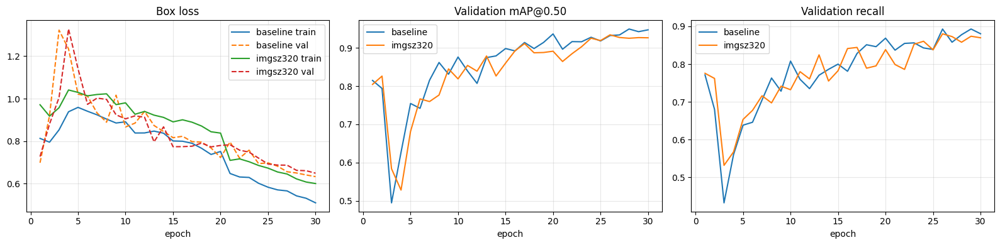

In [ ]:
# Learning curves of both runs on one plot
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name in ["baseline", "imgsz320"]:
    r = pd.read_csv(OUT / f"{name}_results.csv")
    r.columns = [c.strip() for c in r.columns]
    axes[0].plot(r["epoch"], r["train/box_loss"], label=f"{name} train")
    axes[0].plot(r["epoch"], r["val/box_loss"], "--", label=f"{name} val")
    axes[1].plot(r["epoch"], r["metrics/mAP50(B)"], label=name)
    axes[2].plot(r["epoch"], r["metrics/recall(B)"], label=name)
axes[0].set_title("Box loss"); axes[1].set_title("Validation mAP@0.50"); axes[2].set_title("Validation recall")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "learning_curves_comparison.png", dpi=100, bbox_inches="tight")
plt.show()

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2370.0±1240.8 MB/s, size: 95.1 KB)
val: Scanning /content/datasets/african-wildlife-clean/labels/test... 206 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 206/206 2.1Kit/s 0.1s
val: New cache created: /content/datasets/african-wildlife-clean/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.8it/s 2.7s
                   all        206        341      0.971      0.913      0.977      0.828
               buffalo         40         52      0.947      0.904      0.978      0.858
              elephant         56         96      0.967      0.912      0.974      0.782
                 rhino         49         67      0.984      0.939      0.988      0.908
                 zebra         62 

,run,imgsz,precision,recall,mAP@0.50,mAP@0.50:0.95,train_minutes
0,baseline,640,0.971,0.913,0.977,0.828,9.6


Totals over the test set:
gt_objects         341
predicted          372
missed              11
false_detection     42
wrong_class          3
inaccurate_box       6

Images with at least one error: 42 of 206


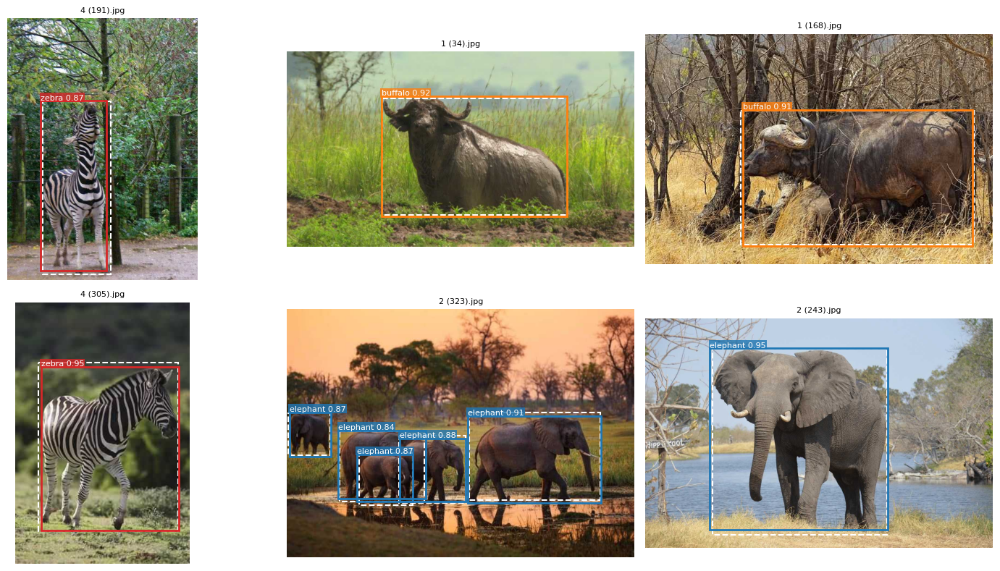

,image,gt_objects,predicted,missed,false_detection,wrong_class,inaccurate_box,errors
175,4 (235).jpg,5,9,0,4,0,1,5
202,4 (75).jpg,8,10,1,3,0,0,4
48,2 (130).jpg,10,9,2,1,0,0,3
67,2 (290).jpg,3,5,0,2,0,0,2
31,1 (373).jpg,4,5,0,1,0,1,2
32,1 (376).jpg,5,4,1,0,0,1,2
135,3 (55).jpg,2,3,0,1,1,0,2
127,3 (329).jpg,2,4,0,2,0,0,2
144,4 (102).jpg,2,4,0,2,0,0,2


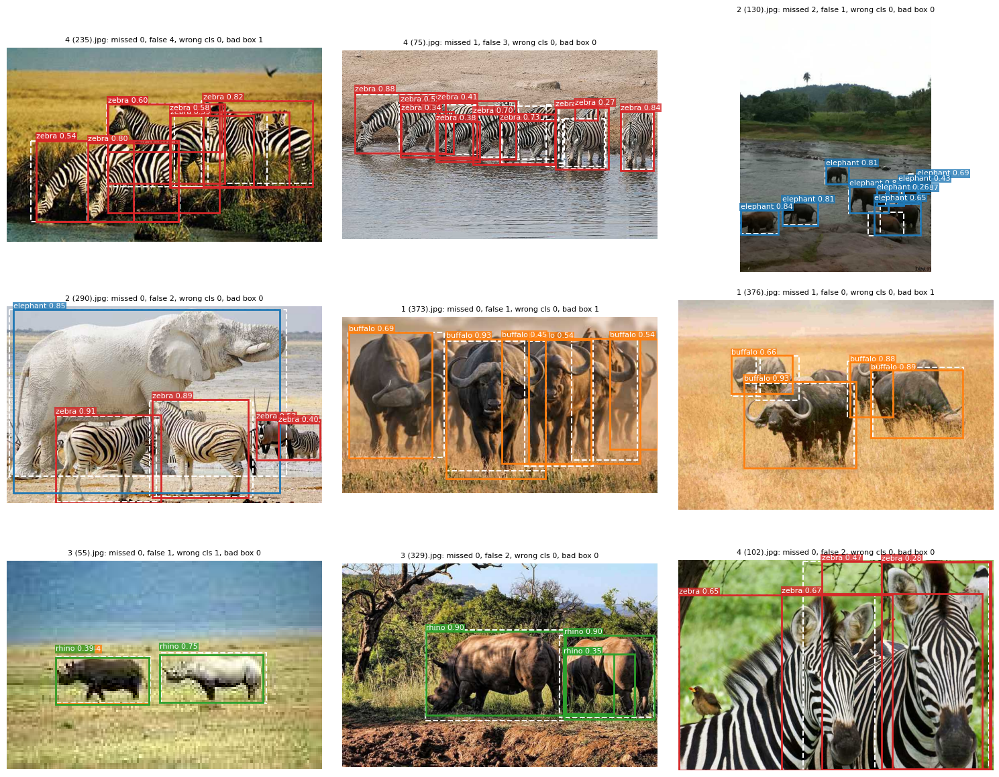

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ===== 4. Final evaluation on the held-out test set =====
# The final run is chosen by VALIDATION mAP@0.50 (baseline 0.948 > imgsz320 0.927).
FINAL = baseline
FINAL_IMGSZ = 640

# 4.1 Test metrics (Ultralytics evaluation: conf=0.001, NMS IoU=0.7, box matching IoU=0.50 for mAP@0.50)
test_metrics = pd.DataFrame([evaluate(FINAL, "test", FINAL_IMGSZ)])
test_metrics.to_csv(OUT / "test_metrics.csv", index=False)
display(test_metrics)

# 4.2 Predictions on test images (for pictures and error analysis: conf=0.25, NMS IoU=0.7)
CONF, MATCH_IOU = 0.25, 0.5
final_model = YOLO(FINAL["best"])

def box_iou(a, b):
    x0, y0 = max(a[0], b[0]), max(a[1], b[1])
    x1, y1 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x1 - x0) * max(0, y1 - y0)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0

records, preds = [], {}
for p in images["test"]:
    r = final_model.predict(str(p), imgsz=FINAL_IMGSZ, conf=CONF, iou=0.7, verbose=False)[0]
    pb = r.boxes.xyxy.cpu().numpy()
    pc = r.boxes.cls.cpu().numpy().astype(int)
    ps = r.boxes.conf.cpu().numpy()
    H, W = r.orig_shape
    gts = [(c, (xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H)
           for c, xc, yc, w, h in (read_labels(p)[0] or [])]
    preds[p] = (pb, pc, ps, gts)

    # match predictions to ground truth (most confident first)
    matched, fp, wrong, bad_box = set(), 0, 0, 0
    for i in np.argsort(-ps):
        best_j, best = -1, 0.0
        for j, g in enumerate(gts):
            if j not in matched:
                v = box_iou(pb[i], g[1:])
                if v > best:
                    best_j, best = j, v
        if best >= MATCH_IOU:
            matched.add(best_j)
            if pc[i] != gts[best_j][0]:
                wrong += 1                       # right place, wrong class
        elif best >= 0.1 and pc[i] == gts[best_j][0]:
            matched.add(best_j); bad_box += 1    # right class, inaccurate box
        else:
            fp += 1                              # detection where there is no animal
    missed = len(gts) - len(matched)
    records.append({"image": p.name, "gt_objects": len(gts), "predicted": len(pb),
                    "missed": missed, "false_detection": fp, "wrong_class": wrong,
                    "inaccurate_box": bad_box, "errors": missed + fp + wrong + bad_box})

errors = pd.DataFrame(records).sort_values("errors", ascending=False)
errors.to_csv(OUT / "test_errors_per_image.csv", index=False)
print("Totals over the test set:")
print(errors[["gt_objects", "predicted", "missed", "false_detection", "wrong_class", "inaccurate_box"]].sum().to_string())
print("\nImages with at least one error:", int((errors.errors > 0).sum()), "of", len(errors))

def draw_pred(ax, p, title=None):
    pb, pc, ps, gts = preds[p]
    ax.imshow(Image.open(p).convert("RGB"))
    for c, x0, y0, x1, y1 in gts:   # ground truth: dashed white
        ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=1.5, ls="--", edgecolor="white"))
    for (x0, y0, x1, y1), c, s in zip(pb, pc, ps):   # predictions: solid colour + class + confidence
        color = COLORS.get(int(c), "yellow")
        ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=2, edgecolor=color))
        ax.text(x0, y0 - 3, f"{CLASS_NAMES[int(c)]} {s:.2f}", color="white", fontsize=8,
                bbox=dict(facecolor=color, alpha=0.8, pad=1, lw=0))
    ax.set_title(title or p.name, fontsize=8)
    ax.axis("off")

def pred_grid(paths, fname, titles=None, cols=3):
    n = int(np.ceil(len(paths) / cols))
    fig, axes = plt.subplots(n, cols, figsize=(5 * cols, 4 * n))
    for ax in np.ravel(axes):
        ax.axis("off")
    for k, (ax, p) in enumerate(zip(np.ravel(axes), paths)):
        draw_pred(ax, p, titles[k] if titles else None)
    plt.tight_layout()
    plt.savefig(OUT / fname, dpi=100, bbox_inches="tight")
    plt.show()

# 4.3 Six random test images with predictions (solid = prediction, dashed white = ground truth)
rng = random.Random(SEED)
pred_grid(rng.sample(images["test"], 6), "test_predictions.png")

# 4.4 The test images with the most errors (candidates for the failure analysis)
by_name = {p.name: p for p in images["test"]}
worst = errors[errors.errors > 0].head(9)
titles = [f"{r.image}: missed {r.missed}, false {r.false_detection}, wrong cls {r.wrong_class}, bad box {r.inaccurate_box}"
          for r in worst.itertuples()]
display(worst)
if len(worst):
    pred_grid([by_name[n] for n in worst.image], "failure_cases.png", titles)

# 4.5 Save everything and download (weights go to a GitHub Release, the zip goes into the repo)
import shutil
from google.colab import files
shutil.copy2(FINAL["best"], "best.pt")
if Path("evidence").exists():
    shutil.rmtree("evidence")
shutil.copytree(OUT, "evidence/outputs")
shutil.copytree("runs", "evidence/runs", ignore=shutil.ignore_patterns("*.pt", "*.cache"))
shutil.make_archive("evidence", "zip", "evidence")
files.download("best.pt")
files.download("evidence.zip")